# SegmentIQ
## Comparative Study of K-Means, Hierarchical and DBSCAN Clustering for Credit Card Customer Segmentation

**Course:** Data Mining & Knowledge Discovery (Assignment 5: Comparative Study based on Clustering)  
**Dataset:** Kaggle Credit Card Dataset for Clustering (`CC GENERAL.csv`, ~8,950 accounts, 17 behavioral attributes)  
**Target Domain:** Financial Analytics, Risk Profiling & Targeted Marketing Strategy  
**Random State:** `random_state=42` applied throughout for 100% deterministic reproducibility  

---

## 📑 Table of Contents
1. [Introduction, Problem Statement & Business Objectives](#section-1)
2. [Data Loading & Variable Type Classification](#section-2)
3. [Data Cleaning, Imputation & Standardization Preprocessing](#section-3)
4. [Exploratory Data Analysis (EDA)](#section-4)
5. [Dimensionality Reduction via 2D and 3D PCA](#section-5)
6. [Hyperparameter Selection & Diagnostic Plots](#section-6)
7. [Clustering Algorithm Implementation (K-Means, Ward, DBSCAN, GMM)](#section-7)
8. [Comprehensive Evaluation & Model Benchmark](#section-8)
9. [In-Depth Sensitivity & Robustness Analyses](#section-9)
10. [Customer Profiling, Persona Engineering & Marketing Strategy](#section-10)
11. [Comparative Analysis Matrix, Limitations & Future Scope](#section-11)

---

<a id="section-1"></a>
## 1. Introduction, Problem Statement, and Business Objectives

### 1.1 The Business Story
Commercial retail banks manage millions of credit card customer accounts. However, treating all cardholders identically results in suboptimal credit limits, high customer churn, wasted marketing expenditures, and elevated default risk:
- **Transactors:** Customers who use cards for daily lifestyle purchases and pay off full balances each billing cycle, generating merchant transaction fee revenue.
- **Revolvers:** Customers who maintain revolving balances month-to-month, generating significant interest yield but carrying default exposure.
- **Cash-Advance Users:** Customers who draw cash from ATMs on credit, incurring high cash-advance fees.
- **Dormant / Low-Usage:** Customers with inactive cards who contribute negligible revenue.

Without labeled customer classes, the bank must rely on **Unsupervised Learning (Clustering)** to uncover organic customer archetypes and deliver personalized products, customized APR promotions, and tailored credit limits.

### 1.2 Core Project Objectives
1. **Unsupervised Segmentation:** Group nearly 9,000 customers into coherent behavioral clusters using 17 transactional attributes.
2. **Comparative Algorithmic Benchmark:** Compare Partitioning (**K-Means**), Agglomerative Hierarchical (**Ward Linkage**), Density-Based (**DBSCAN**), and Probabilistic (**Gaussian Mixture Model**).
3. **Internal Validation:** Benchmark models using **Silhouette Score**, **Davies-Bouldin Index**, and **Calinski-Harabasz Index**, while measuring computational runtime in seconds.
4. **Actionable Commercial Playbooks:** Translate mathematical cluster centroids into real-world banking personas with targeted commercial recommendations.

<a id="section-2"></a>
## 2. Data Ingestion & Variable Classification

### What is done:
We load the dataset `CC_GENERAL.csv` into a Pandas DataFrame, inspect its dimensions, column types, and display representative records. We construct an academic variable audit table classifying every column into **Nominal/Numeric** and **Discrete/Continuous**.

### Why:
Understanding variable scales dictates preprocessing needs: continuous monetary metrics require standard scaling, discrete counts require careful distribution audits, and arbitrary categorical identifiers must be removed from geometric distance computations.

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.neighbors import NearestNeighbors
import warnings
warnings.filterwarnings('ignore')

# Set aesthetic styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

# Load dataset using relative path
DATA_PATH = "CC_GENERAL.csv" if os.path.exists("CC_GENERAL.csv") else os.path.join("data", "CC_GENERAL.csv")
df_raw = pd.read_csv(DATA_PATH)

print(f"SegmentIQ Dataset Successfully Loaded!")
print(f"Total Customer Accounts (Rows):     {df_raw.shape[0]:,}")
print(f"Total Recorded Features (Columns):  {df_raw.shape[1]}")
df_raw.head()

SegmentIQ Dataset Successfully Loaded!
Total Customer Accounts (Rows):     8,950
Total Recorded Features (Columns):  18


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


### Variable Classification Table
Here we systematically audit data types, unique counts, missing rates, and statistical measurement scales.

In [2]:
# Build variable classification table
audit_records = []
for col in df_raw.columns:
    n_unique = df_raw[col].nunique()
    n_missing = int(df_raw[col].isnull().sum())
    pct_missing = (n_missing / len(df_raw)) * 100
    dtype = str(df_raw[col].dtype)
    
    if col == "CUST_ID":
        classification = "Nominal (Categorical ID)"
        scale = "Discrete"
    elif n_unique <= 20:
        classification = "Discrete Numeric (Count / Scale)"
        scale = "Discrete"
    else:
        classification = "Continuous Numeric (Monetary / Frequency)"
        scale = "Continuous"
        
    audit_records.append({
        "Feature": col,
        "Data Type": dtype,
        "Unique Values": n_unique,
        "Missing Count": n_missing,
        "Missing %": round(pct_missing, 2),
        "Classification": classification,
        "Measurement Scale": scale
    })

audit_df = pd.DataFrame(audit_records)
audit_df

,Feature,Data Type,Unique Values,Missing Count,Missing %,Classification,Measurement Scale
0,CUST_ID,object,8950,0,0.00,Nominal (Categorical ID),Discrete
1,BALANCE,float64,8871,0,0.00,Continuous Numeric (Monetary / Frequency),Continuous
2,BALANCE_FREQUENCY,float64,43,0,0.00,Continuous Numeric (Monetary / Frequency),Continuous
3,PURCHASES,float64,6203,0,0.00,Continuous Numeric (Monetary / Frequency),Continuous
4,ONEOFF_PURCHASES,float64,4014,0,0.00,Continuous Numeric (Monetary / Frequency),Continuous
5,INSTALLMENTS_PURCHASES,float64,4452,0,0.00,Continuous Numeric (Monetary / Frequency),Continuous
6,CASH_ADVANCE,float64,4323,0,0.00,Continuous Numeric (Monetary / Frequency),Continuous
7,PURCHASES_FREQUENCY,float64,47,0,0.00,Continuous Numeric (Monetary / Frequency),Continuous
8,ONEOFF_PURCHASES_FREQUENCY,float64,47,0,0.00,Continuous Numeric (Monetary / Frequency),Continuous
9,PURCHASES_INSTALLMENTS_FREQUENCY,float64,47,0,0.00,Continuous Numeric (Monetary / Frequency),Continuous


<a id="section-3"></a>
## 3. Preprocessing, Imputation & Feature Scaling

### What is done:
1. **Missing Value Imputation:** Identify missing values and impute them with the **Median**.
2. **Dropping Identifier:** Remove `CUST_ID` to eliminate non-behavioral categorical noise.
3. **Duplicate Verification:** Verify that all customer observations are unique.
4. **Skewness & IQR Outlier Analysis:** Compute parametric skewness and count outliers using Tukey's $1.5 \times \text{IQR}$ rule.
5. **StandardScaler Normalization:** Transform all continuous features to $\mu = 0$ and $\sigma = 1$.
6. **Distribution Comparison:** Plot distributions before and after scaling.

### Why:
- **Why Median Imputation?** Features such as `MINIMUM_PAYMENTS` exhibit extreme positive skewness (most customers pay several hundred dollars, while rare outliers pay tens of thousands). Imputing with the arithmetic mean would artificially pull values upward; the median provides a robust, representative measure of central tendency.
- **Why StandardScaler?** Clustering algorithms compute Euclidean distances:
  $$d(p, q) = \sqrt{\sum_{i=1}^n (p_i - q_i)^2}$$
  Without standardization, large-magnitude features like `CREDIT_LIMIT` ($0 to $30,000) completely drown out frequencies ($0.0 to 1.0$) and bias cluster boundaries.

In [3]:
# Check missing value counts
missing_summary = df_raw.isnull().sum()
missing_features = missing_summary[missing_summary > 0]
print("Features Requiring Imputation:")
print(missing_features)

# Check duplicates
print(f"\nDuplicate Records Detected: {df_raw.duplicated().sum()}")

# 1. Drop CUST_ID
df_clean = df_raw.drop(columns=["CUST_ID"])
feature_cols = df_clean.columns.tolist()

# 2. Median Imputation
imputation_medians = df_clean.median()
for col in missing_features.index:
    median_val = float(imputation_medians[col])
    df_clean[col].fillna(median_val, inplace=True)
    print(f"Imputed missing '{col}' with Median: {median_val:.2f}")

print(f"Remaining Missing Values: {df_clean.isnull().sum().sum()}")

Features Requiring Imputation:
CREDIT_LIMIT          1
MINIMUM_PAYMENTS    313
dtype: int64

Duplicate Records Detected: 0
Imputed missing 'CREDIT_LIMIT' with Median: 3000.00
Imputed missing 'MINIMUM_PAYMENTS' with Median: 312.34
Remaining Missing Values: 0


### Skewness & Interquartile Range (IQR) Outlier Analysis
We quantify distribution asymmetry and count extreme outliers using the Interquartile Range formula:
$$\text{IQR} = Q_3 - Q_1, \quad \text{Lower} = Q_1 - 1.5 \times \text{IQR}, \quad \text{Upper} = Q_3 + 1.5 \times \text{IQR}$$

In [4]:
# Compute IQR Outliers and Skewness
outlier_records = []
for col in feature_cols:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr
    outlier_count = int(((df_clean[col] < lower_limit) | (df_clean[col] > upper_limit)).sum())
    skew_val = df_clean[col].skew()
    
    outlier_records.append({
        "Feature": col,
        "Skewness": round(float(skew_val), 2),
        "Q1": round(float(q1), 2),
        "Median": round(float(df_clean[col].median()), 2),
        "Q3": round(float(q3), 2),
        "IQR": round(float(iqr), 2),
        "Outliers": outlier_count,
        "Outlier %": round((outlier_count / len(df_clean)) * 100, 2)
    })

outlier_df = pd.DataFrame(outlier_records)
outlier_df.sort_values(by="Outlier %", ascending=False)

,Feature,Skewness,Q1,Median,Q3,IQR,Outliers,Outlier %
1,BALANCE_FREQUENCY,-2.02,0.89,1.00,1.00,0.11,1493,16.68
15,PRC_FULL_PAYMENT,1.94,0.00,0.00,0.14,0.14,1474,16.47
16,TENURE,-2.94,12.00,12.00,12.00,0.00,1366,15.26
5,CASH_ADVANCE,5.17,0.00,0.00,1113.82,1113.82,1030,11.51
3,ONEOFF_PURCHASES,10.05,0.00,38.00,577.40,577.40,1013,11.32
14,MINIMUM_PAYMENTS,13.85,170.86,312.34,788.71,617.86,909,10.16
4,INSTALLMENTS_PURCHASES,7.30,0.00,89.00,468.64,468.64,867,9.69
13,PAYMENTS,5.91,383.28,856.90,1901.13,1517.86,808,9.03
2,PURCHASES,8.14,39.63,361.28,1110.13,1070.50,808,9.03
10,CASH_ADVANCE_TRX,5.72,0.00,0.00,4.00,4.00,804,8.98


### StandardScaler Transformation & Visual Comparison
We standardize our features so every dimension has mean $\mu = 0$ and standard deviation $\sigma = 1$:
$$z = \frac{x - \mu}{\sigma}$$

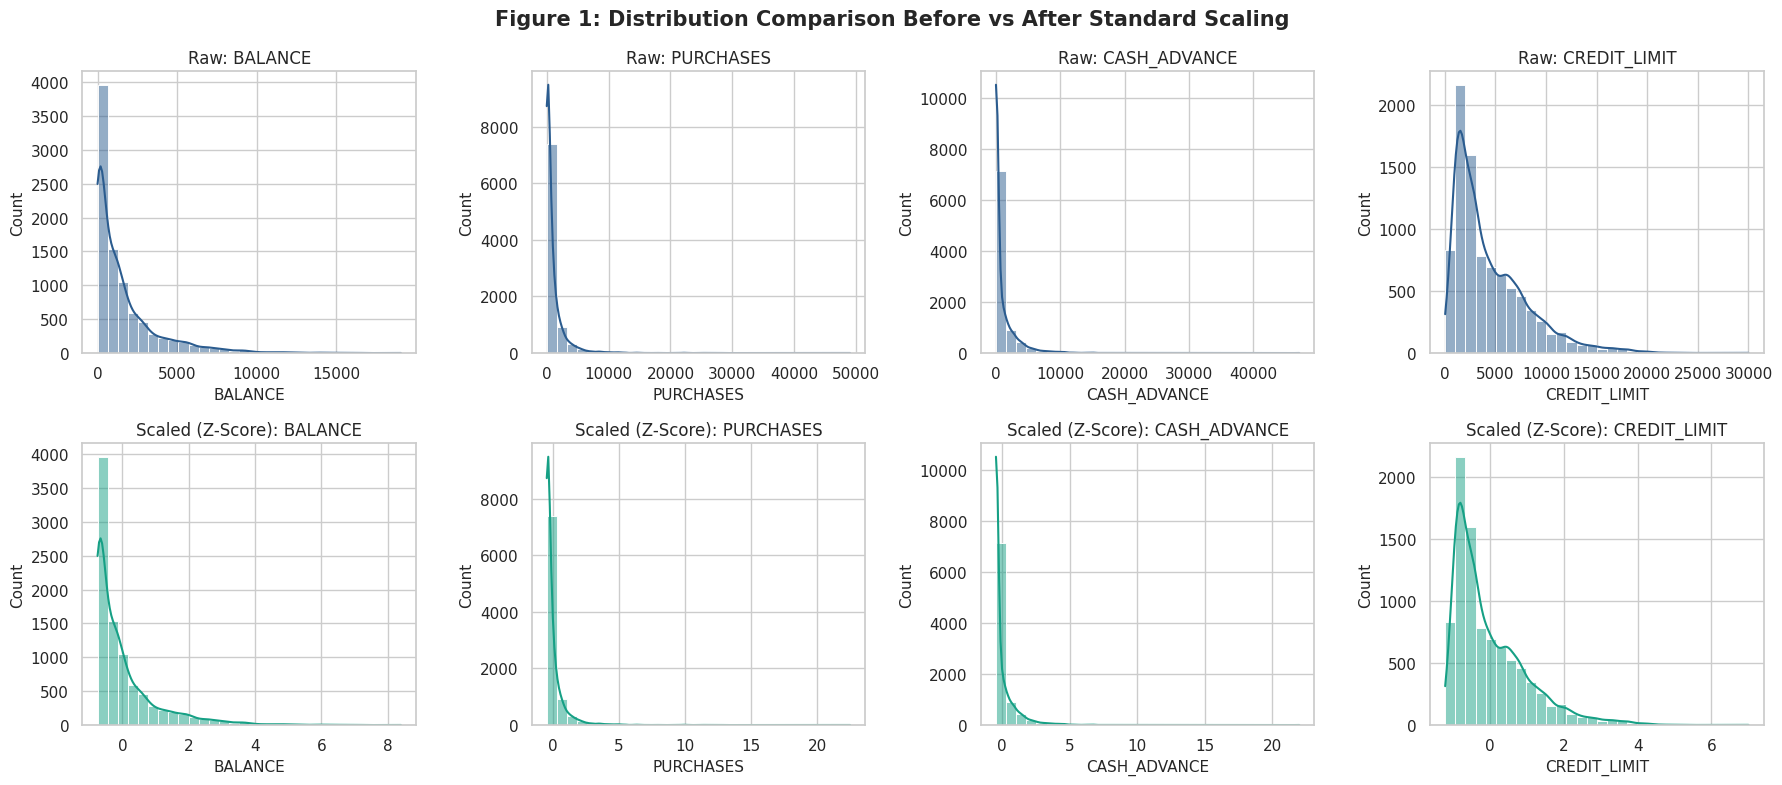

In [5]:
# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_clean)
df_scaled = pd.DataFrame(X_scaled, columns=feature_cols)

# Visualize Before vs After Scaling for 4 Key Financial Features
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
key_feats = ["BALANCE", "PURCHASES", "CASH_ADVANCE", "CREDIT_LIMIT"]

for i, col in enumerate(key_feats):
    # Before scaling (Raw)
    sns.histplot(df_clean[col], kde=True, ax=axes[0, i], color="#2b5c8f", bins=30)
    axes[0, i].set_title(f"Raw: {col}")
    axes[0, i].set_ylabel("Count")
    
    # After scaling (Standardized)
    sns.histplot(df_scaled[col], kde=True, ax=axes[1, i], color="#16a085", bins=30)
    axes[1, i].set_title(f"Scaled (Z-Score): {col}")
    axes[1, i].set_ylabel("Count")

plt.suptitle("Figure 1: Distribution Comparison Before vs After Standard Scaling", fontsize=15, weight='bold')
plt.tight_layout()
plt.show()

<a id="section-4"></a>
## 4. Exploratory Data Analysis (EDA)

### What is done:
We compile summary descriptive statistics (Mean, Median, Standard Deviation, IQR), generate standardized boxplots, and compute a full Pearson correlation heatmap.

### Why:
Exploratory data analysis reveals underlying behavioral variance and multi-collinearity across cardholder activities before running unsupervised algorithms.

In [6]:
# Statistical Descriptive Summary Table
summary_stats = []
for col in feature_cols:
    summary_stats.append({
        "Feature": col,
        "Mean": round(float(df_clean[col].mean()), 2),
        "Std Dev": round(float(df_clean[col].std()), 2),
        "Median": round(float(df_clean[col].median()), 2),
        "IQR": round(float(df_clean[col].quantile(0.75) - df_clean[col].quantile(0.25)), 2),
        "Min": round(float(df_clean[col].min()), 2),
        "Max": round(float(df_clean[col].max()), 2)
    })

summary_table = pd.DataFrame(summary_stats)
summary_table

,Feature,Mean,Std Dev,Median,IQR,Min,Max
0,BALANCE,1564.47,2081.53,873.39,1925.86,0.00,19043.14
1,BALANCE_FREQUENCY,0.88,0.24,1.00,0.11,0.00,1.00
2,PURCHASES,1003.20,2136.63,361.28,1070.50,0.00,49039.57
3,ONEOFF_PURCHASES,592.44,1659.89,38.00,577.40,0.00,40761.25
4,INSTALLMENTS_PURCHASES,411.07,904.34,89.00,468.64,0.00,22500.00
5,CASH_ADVANCE,978.87,2097.16,0.00,1113.82,0.00,47137.21
6,PURCHASES_FREQUENCY,0.49,0.40,0.50,0.83,0.00,1.00
7,ONEOFF_PURCHASES_FREQUENCY,0.20,0.30,0.08,0.30,0.00,1.00
8,PURCHASES_INSTALLMENTS_FREQUENCY,0.36,0.40,0.17,0.75,0.00,1.00
9,CASH_ADVANCE_FREQUENCY,0.14,0.20,0.00,0.22,0.00,1.50


### Feature Boxplots & Distribution Spread

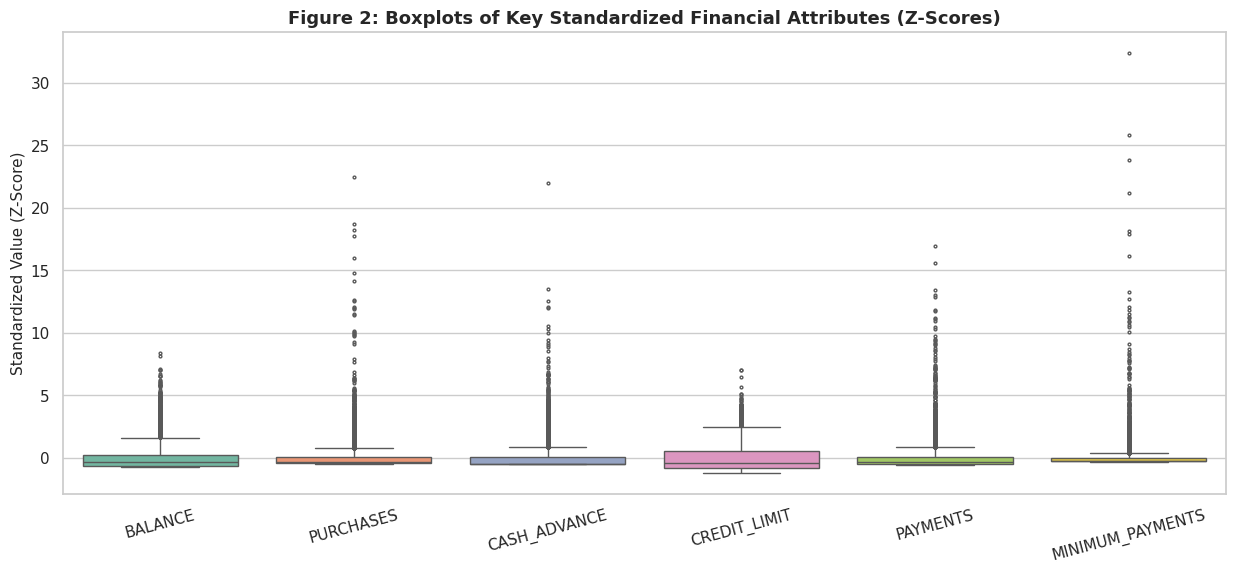

In [7]:
# Boxplots of Key Features (Standardized Scale)
plt.figure(figsize=(15, 6))
sns.boxplot(data=df_scaled[["BALANCE", "PURCHASES", "CASH_ADVANCE", "CREDIT_LIMIT", "PAYMENTS", "MINIMUM_PAYMENTS"]], 
            palette="Set2", fliersize=2)
plt.title("Figure 2: Boxplots of Key Standardized Financial Attributes (Z-Scores)", fontsize=13, weight='bold')
plt.ylabel("Standardized Value (Z-Score)")
plt.xticks(rotation=15)
plt.show()

### Correlation Heatmap

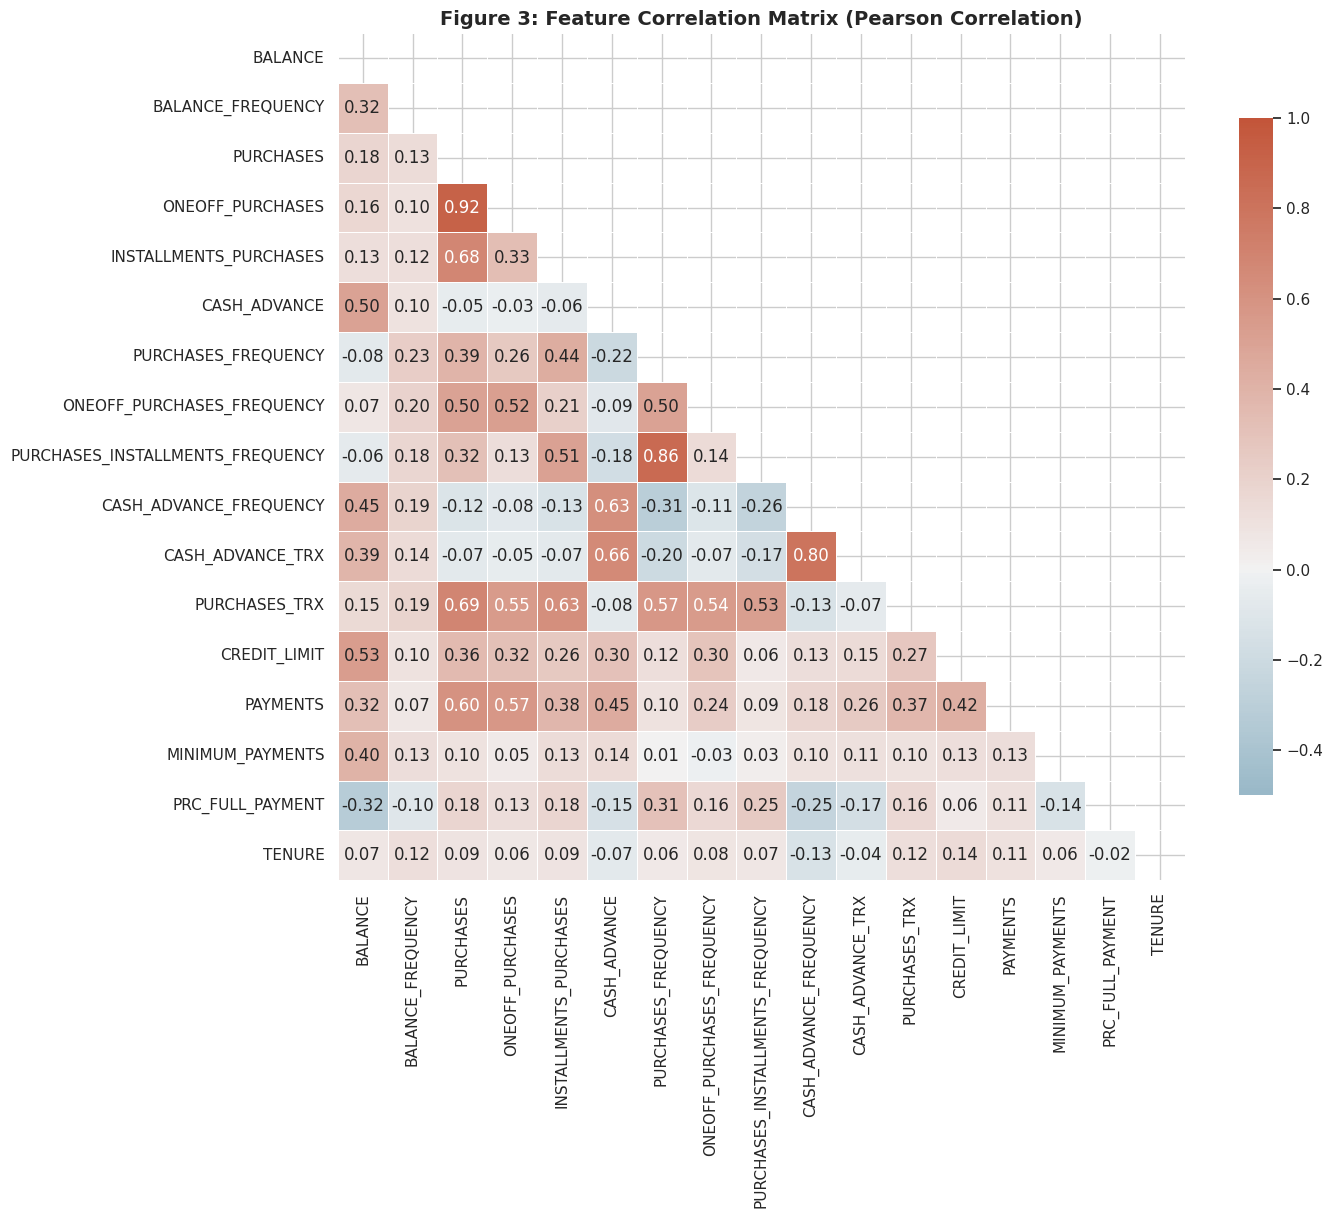

In [8]:
# Pearson Correlation Matrix
plt.figure(figsize=(14, 11))
corr_matrix = df_clean.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
cmap = sns.diverging_palette(230, 20, as_cmap=True)

sns.heatmap(corr_matrix, mask=mask, cmap=cmap, vmin=-0.5, vmax=1.0, center=0,
            annot=True, fmt=".2f", square=True, linewidths=.5, cbar_kws={"shrink": .8})
plt.title("Figure 3: Feature Correlation Matrix (Pearson Correlation)", fontsize=14, weight='bold')
plt.show()

<a id="section-5"></a>
## 5. Dimensionality Reduction via 2D and 3D PCA

### What is done:
We project the 17-dimensional standardized dataset onto **2-dimensional** and **3-dimensional** orthogonal coordinate spaces using **Principal Component Analysis (PCA)**. We report the explained variance ratio for each component individually and cumulatively for both 2D and 3D representations.

### Why:
High-dimensional datasets cannot be directly plotted on a screen. PCA identifies orthogonal linear combinations that capture maximum variance, enabling rich 2D and 3D spatial visualizations of cluster cohesion, separation, and density without modifying the underlying 17-dimensional model training.

--- Principal Component Analysis (PCA) Explained Variance ---
Principal Component 1 (PC1):           27.30%
Principal Component 2 (PC2):           20.31%
Principal Component 3 (PC3):           8.81%
Cumulative 2-Component Explained Var:  47.61%
Cumulative 3-Component Explained Var:  56.42%


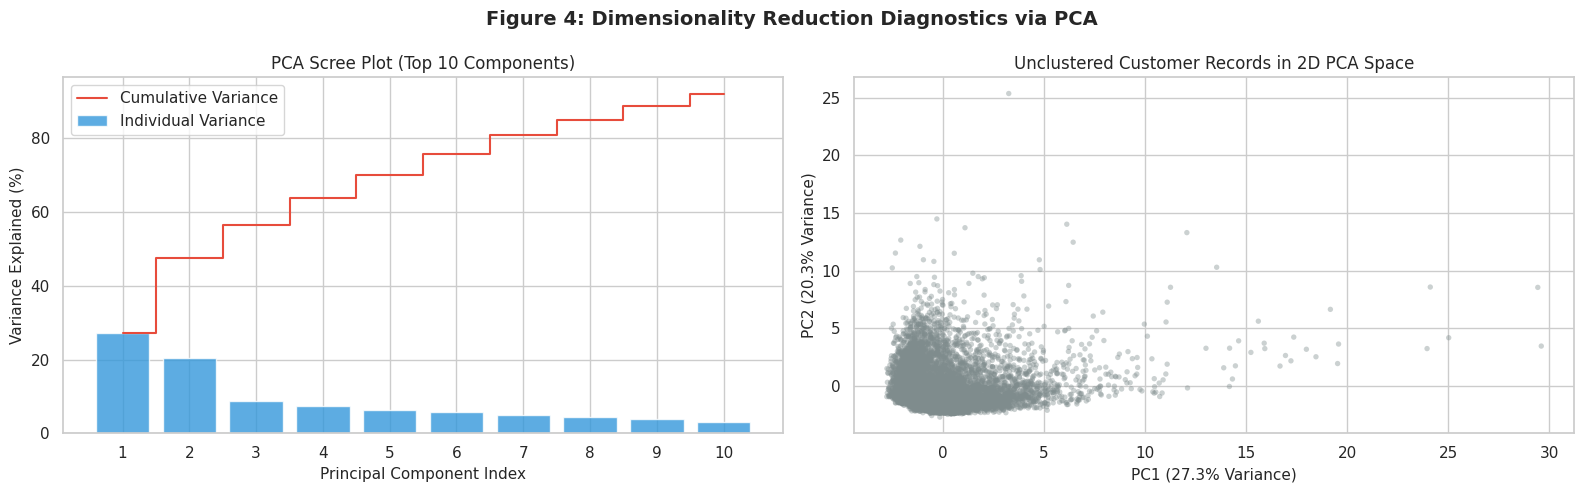

In [9]:
# Compute 2D and 3D PCA Projections
pca_3d = PCA(n_components=3, random_state=42)
X_pca_3d = pca_3d.fit_transform(X_scaled)
X_pca_2d = X_pca_3d[:, :2]

var_c1, var_c2, var_c3 = pca_3d.explained_variance_ratio_
cum_var_2d = var_c1 + var_c2
cum_var_3d = var_c1 + var_c2 + var_c3

print("--- Principal Component Analysis (PCA) Explained Variance ---")
print(f"Principal Component 1 (PC1):           {var_c1 * 100:.2f}%")
print(f"Principal Component 2 (PC2):           {var_c2 * 100:.2f}%")
print(f"Principal Component 3 (PC3):           {var_c3 * 100:.2f}%")
print(f"Cumulative 2-Component Explained Var:  {cum_var_2d * 100:.2f}%")
print(f"Cumulative 3-Component Explained Var:  {cum_var_3d * 100:.2f}%")

# Scree Plot of Top 10 Components
pca_full = PCA(n_components=10, random_state=42).fit(X_scaled)

fig, ax = plt.subplots(1, 2, figsize=(16, 5))

# Scree Plot
ax[0].bar(range(1, 11), pca_full.explained_variance_ratio_ * 100, color="#3498db", alpha=0.8, label="Individual Variance")
ax[0].step(range(1, 11), np.cumsum(pca_full.explained_variance_ratio_) * 100, where='mid', color="#e74c3c", label="Cumulative Variance")
ax[0].set_xlabel("Principal Component Index")
ax[0].set_ylabel("Variance Explained (%)")
ax[0].set_title("PCA Scree Plot (Top 10 Components)")
ax[0].legend()
ax[0].set_xticks(range(1, 11))

# Unclustered 2D PCA Space
ax[1].scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], c="#7f8c8d", alpha=0.4, s=15, edgecolors='none')
ax[1].set_xlabel(f"PC1 ({var_c1*100:.1f}% Variance)")
ax[1].set_ylabel(f"PC2 ({var_c2*100:.1f}% Variance)")
ax[1].set_title("Unclustered Customer Records in 2D PCA Space")

plt.suptitle("Figure 4: Dimensionality Reduction Diagnostics via PCA", fontsize=14, weight='bold')
plt.tight_layout()
plt.show()

<a id="section-6"></a>
## 6. Hyperparameter Selection & Diagnostic Plots

### What is done:
1. **K-Means Parameter Selection:**
   - **Elbow Method:** Compute Within-Cluster Sum of Squares (Inertia SSE) across $k \in [2, 10]$ to locate the bend.
   - **Silhouette Analysis:** Compute mean Silhouette coefficients for $k \in [2, 10]$ to find the peak cluster separation.
2. **Hierarchical Parameter Selection:**
   - **Ward Dendrogram:** Build an agglomerative hierarchical tree using Ward linkage on a representative sample to determine the natural cutting threshold.
3. **DBSCAN Parameter Selection:**
   - **k-Distance Graph:** Calculate distance to the $k$-th nearest neighbor ($k = 5$) and sort distances ascending to identify the knee for $\varepsilon$.

### Why:
Unsupervised models require objective hyperparameter selection. Arbitrary choices lead to artificial segmentations; grounding parameters in quantitative curves ensures optimal cluster validity.

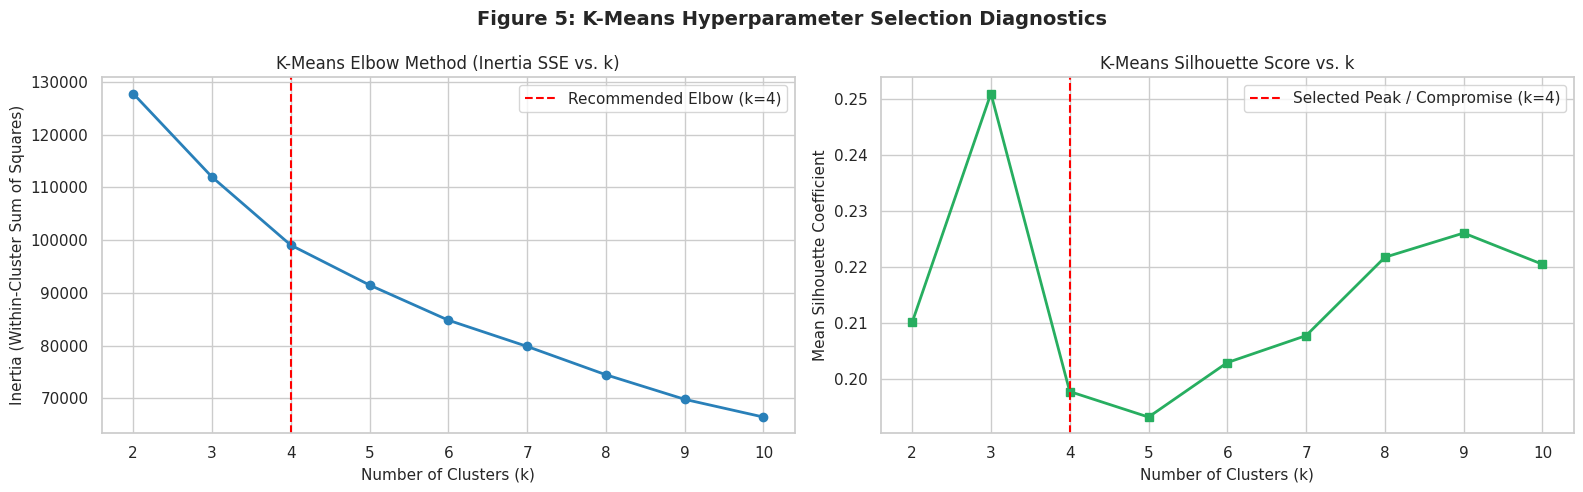

In [10]:
# 1. K-Means: Elbow Method & Silhouette Curves
k_range = range(2, 11)
inertias = []
silhouettes_kmeans = []

for k in k_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    km_labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes_kmeans.append(silhouette_score(X_scaled, km_labels, random_state=42))

fig, ax = plt.subplots(1, 2, figsize=(16, 5))

# Elbow Plot
ax[0].plot(k_range, inertias, marker='o', linewidth=2, color='#2980b9')
ax[0].set_title("K-Means Elbow Method (Inertia SSE vs. k)")
ax[0].set_xlabel("Number of Clusters (k)")
ax[0].set_ylabel("Inertia (Within-Cluster Sum of Squares)")
ax[0].set_xticks(list(k_range))
ax[0].axvline(x=4, color='red', linestyle='--', label="Recommended Elbow (k=4)")
ax[0].legend()

# Silhouette Plot
ax[1].plot(k_range, silhouettes_kmeans, marker='s', linewidth=2, color='#27ae60')
ax[1].set_title("K-Means Silhouette Score vs. k")
ax[1].set_xlabel("Number of Clusters (k)")
ax[1].set_ylabel("Mean Silhouette Coefficient")
ax[1].set_xticks(list(k_range))
ax[1].axvline(x=4, color='red', linestyle='--', label="Selected Peak / Compromise (k=4)")
ax[1].legend()

plt.suptitle("Figure 5: K-Means Hyperparameter Selection Diagnostics", fontsize=14, weight='bold')
plt.tight_layout()
plt.show()

### Hierarchical Dendrogram (Ward Linkage)
Ward's criterion minimizes within-cluster variance at each merge. We sample 1,000 observations to produce a crisp, interpretable dendrogram.

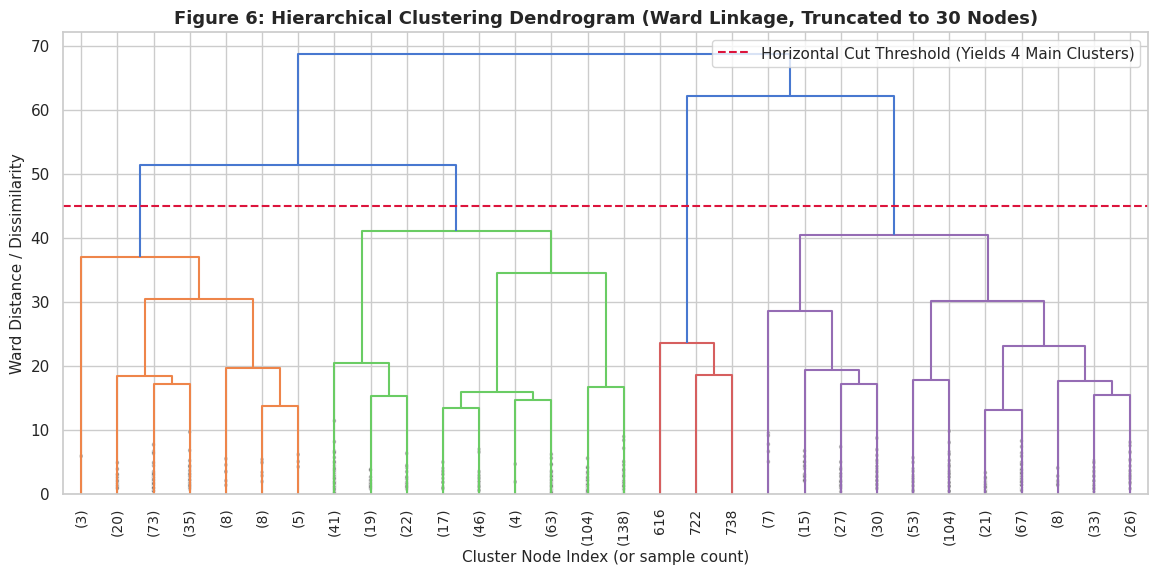

In [11]:
# Hierarchical Dendrogram using Ward Linkage (Sampled 1000 observations)
np.random.seed(42)
sample_idx = np.random.choice(X_scaled.shape[0], size=1000, replace=False)
X_dendro_sample = X_scaled[sample_idx]

linkage_matrix = linkage(X_dendro_sample, method='ward')

plt.figure(figsize=(14, 6))
dendrogram(linkage_matrix, truncate_mode='lastp', p=30, leaf_rotation=90., leaf_font_size=10., show_contracted=True)
plt.title("Figure 6: Hierarchical Clustering Dendrogram (Ward Linkage, Truncated to 30 Nodes)", fontsize=13, weight='bold')
plt.xlabel("Cluster Node Index (or sample count)")
plt.ylabel("Ward Distance / Dissimilarity")
plt.axhline(y=45, color='crimson', linestyle='--', label="Horizontal Cut Threshold (Yields 4 Main Clusters)")
plt.legend()
plt.show()

### DBSCAN k-Distance Graph for $\varepsilon$ Determination
We plot the distance of each customer observation to its 5th nearest neighbor in ascending order. The knee point represents the boundary where points transition into sparse outliers.

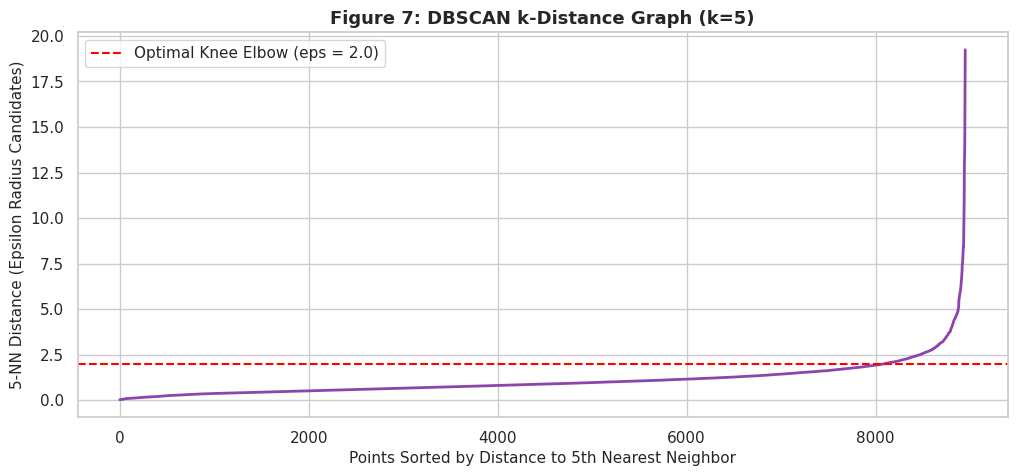

In [12]:
# k-distance graph for min_samples = 5
min_samples_val = 5
neighbors = NearestNeighbors(n_neighbors=min_samples_val)
neighbors_fit = neighbors.fit(X_scaled)
distances, indices = neighbors_fit.kneighbors(X_scaled)

k_distances = np.sort(distances[:, min_samples_val - 1])

plt.figure(figsize=(12, 5))
plt.plot(k_distances, color="#8e44ad", linewidth=2)
plt.title("Figure 7: DBSCAN k-Distance Graph (k=5)", fontsize=13, weight='bold')
plt.xlabel("Points Sorted by Distance to 5th Nearest Neighbor")
plt.ylabel("5-NN Distance (Epsilon Radius Candidates)")
plt.axhline(y=2.0, color='red', linestyle='--', label="Optimal Knee Elbow (eps = 2.0)")
plt.legend()
plt.show()

<a id="section-7"></a>
## 7. Model Implementation: K-Means, Agglomerative, DBSCAN & GMM

### What is done:
We train all four clustering models on the standardized 17-dimensional feature space ($N = 8,950$):
1. **K-Means:** $k=4$, `init='k-means++'`, `random_state=42`
2. **Agglomerative (Hierarchical):** $k=4$, `linkage='ward'`
3. **DBSCAN:** $\varepsilon=2.0$, `min_samples=5`
4. **Gaussian Mixture Model (GMM):** $k=4$, `covariance_type='full'`, `random_state=42`

We record precise training runtimes using high-precision performance timers.

### Why:
Training multiple algorithms highlights trade-offs: K-Means produces spherical Voronoi partitions; Agglomerative builds a hierarchical merge tree; DBSCAN separates arbitrary-density manifolds and flags noise; GMM estimates soft Gaussian probability distributions.

In [13]:
# 1. K-Means
t0 = time.perf_counter()
kmeans = KMeans(n_clusters=4, init='k-means++', n_init=10, random_state=42)
labels_kmeans = kmeans.fit_predict(X_scaled)
time_kmeans = time.perf_counter() - t0

# 2. Agglomerative (Hierarchical)
t0 = time.perf_counter()
agg = AgglomerativeClustering(n_clusters=4, linkage='ward')
labels_agg = agg.fit_predict(X_scaled)
time_agg = time.perf_counter() - t0

# 3. DBSCAN
t0 = time.perf_counter()
dbscan = DBSCAN(eps=2.0, min_samples=5)
labels_dbscan = dbscan.fit_predict(X_scaled)
time_dbscan = time.perf_counter() - t0

# 4. Gaussian Mixture Model (GMM)
t0 = time.perf_counter()
gmm = GaussianMixture(n_components=4, covariance_type='full', random_state=42)
labels_gmm = gmm.fit_predict(X_scaled)
time_gmm = time.perf_counter() - t0

print(f"K-Means Execution Time:       {time_kmeans:.4f} seconds")
print(f"Agglomerative Execution Time: {time_agg:.4f} seconds")
print(f"DBSCAN Execution Time:        {time_dbscan:.4f} seconds")
print(f"GMM Execution Time:           {time_gmm:.4f} seconds")

K-Means Execution Time:       0.1004 seconds
Agglomerative Execution Time: 2.5114 seconds
DBSCAN Execution Time:        0.2185 seconds
GMM Execution Time:           0.6977 seconds


<a id="section-8"></a>
## 8. Comparative Evaluation & Benchmark Visualizations

### What is done:
1. **Validation Metrics:** Compute **Silhouette Score** (higher is better $[-1, 1]$), **Davies-Bouldin Index** (lower is better $[0, \infty)$), and **Calinski-Harabasz Index** (higher is better).
2. **Noise Handling:** **Crucially, DBSCAN noise points (labeled $-1$) are excluded when calculating internal clustering validation metrics.** Metric definitions require valid cluster assignment; including noise points would distort cluster centroids and yield invalid inter-cluster distances.
3. **Comparison Table:** Synthesize all metrics, cluster counts, noise counts, and runtimes into a formatted benchmark table.
4. **Visual Comparison:** Create side-by-side metric bar charts and a 4-panel 2D PCA scatter plot.

In [14]:
def compute_metrics(X, labels, runtime):
    unique = np.unique(labels)
    noise_count = int(np.sum(labels == -1)) if -1 in unique else 0
    
    # Exclude noise points (-1) for density clustering
    mask = labels != -1
    clean_labels = labels[mask]
    clean_X = X[mask]
    n_valid_clusters = len(np.unique(clean_labels))
    
    if n_valid_clusters >= 2 and len(clean_labels) > n_valid_clusters:
        sil = silhouette_score(clean_X, clean_labels, random_state=42)
        db = davies_bouldin_score(clean_X, clean_labels)
        ch = calinski_harabasz_score(clean_X, clean_labels)
    else:
        sil, db, ch = np.nan, np.nan, np.nan
        
    return {
        "Valid Clusters": n_valid_clusters,
        "Noise Points": noise_count,
        "Silhouette Score (↑)": round(sil, 4) if not np.isnan(sil) else None,
        "Davies-Bouldin Index (↓)": round(db, 4) if not np.isnan(db) else None,
        "Calinski-Harabasz Index (↑)": round(ch, 2) if not np.isnan(ch) else None,
        "Runtime (seconds)": round(runtime, 4)
    }

# Benchmark all 4 models
metrics_dict = {
    "K-Means (k=4)": compute_metrics(X_scaled, labels_kmeans, time_kmeans),
    "Hierarchical (Ward, k=4)": compute_metrics(X_scaled, labels_agg, time_agg),
    "DBSCAN (eps=2.0, min=5)": compute_metrics(X_scaled, labels_dbscan, time_dbscan),
    "GMM (k=4)": compute_metrics(X_scaled, labels_gmm, time_gmm)
}

comparison_df = pd.DataFrame(metrics_dict).T
comparison_df

,Valid Clusters,Noise Points,Silhouette Score (↑),Davies-Bouldin Index (↓),Calinski-Harabasz Index (↑),Runtime (seconds)
K-Means (k=4),4.0,0.0,0.1977,1.5748,1598.08,0.1004
"Hierarchical (Ward, k=4)",4.0,0.0,0.1598,1.7503,1223.61,2.5114
"DBSCAN (eps=2.0, min=5)",2.0,599.0,0.4460,0.6144,24.86,0.2185
GMM (k=4),4.0,0.0,0.1037,2.6451,762.60,0.6977


### Metric Comparison Bar Charts & Side-by-Side PCA Scatter Plots

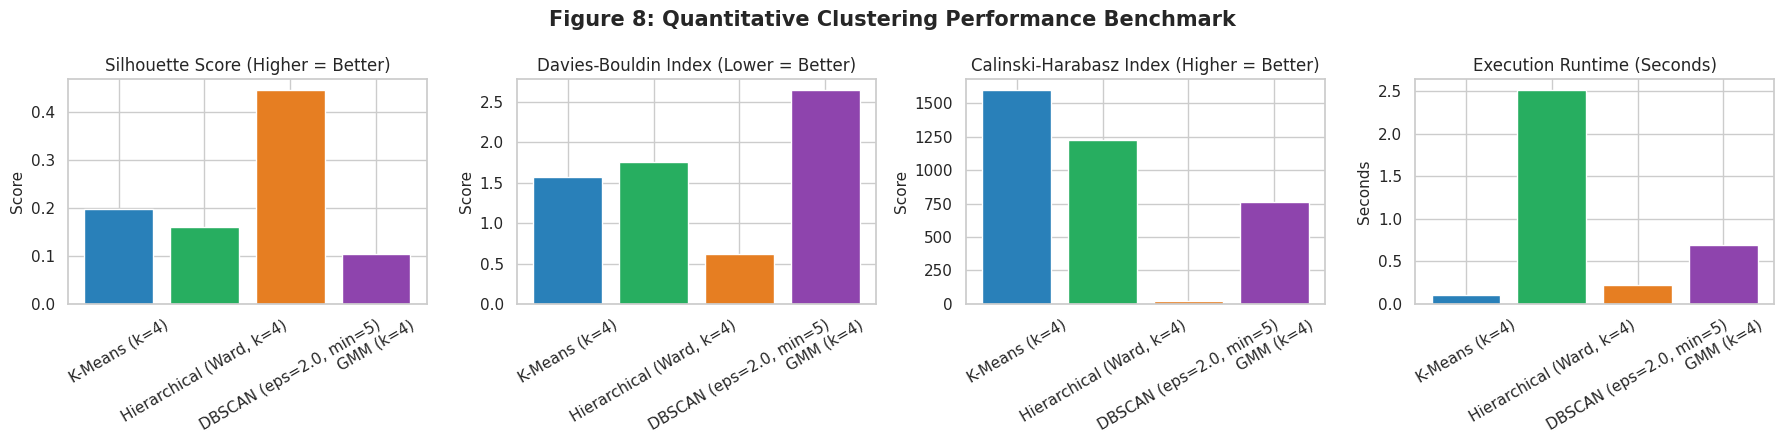

In [15]:
# 1. Bar Chart Comparison
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
models = list(metrics_dict.keys())

# Silhouette
sil_vals = [metrics_dict[m]["Silhouette Score (↑)"] for m in models]
axes[0].bar(models, sil_vals, color=['#2980b9', '#27ae60', '#e67e22', '#8e44ad'])
axes[0].set_title("Silhouette Score (Higher = Better)")
axes[0].set_ylabel("Score")
axes[0].tick_params(axis='x', rotation=30)

# Davies-Bouldin
db_vals = [metrics_dict[m]["Davies-Bouldin Index (↓)"] for m in models]
axes[1].bar(models, db_vals, color=['#2980b9', '#27ae60', '#e67e22', '#8e44ad'])
axes[1].set_title("Davies-Bouldin Index (Lower = Better)")
axes[1].set_ylabel("Score")
axes[1].tick_params(axis='x', rotation=30)

# Calinski-Harabasz
ch_vals = [metrics_dict[m]["Calinski-Harabasz Index (↑)"] for m in models]
axes[2].bar(models, ch_vals, color=['#2980b9', '#27ae60', '#e67e22', '#8e44ad'])
axes[2].set_title("Calinski-Harabasz Index (Higher = Better)")
axes[2].set_ylabel("Score")
axes[2].tick_params(axis='x', rotation=30)

# Runtime
rt_vals = [metrics_dict[m]["Runtime (seconds)"] for m in models]
axes[3].bar(models, rt_vals, color=['#2980b9', '#27ae60', '#e67e22', '#8e44ad'])
axes[3].set_title("Execution Runtime (Seconds)")
axes[3].set_ylabel("Seconds")
axes[3].tick_params(axis='x', rotation=30)

plt.suptitle("Figure 8: Quantitative Clustering Performance Benchmark", fontsize=15, weight='bold')
plt.tight_layout()
plt.show()

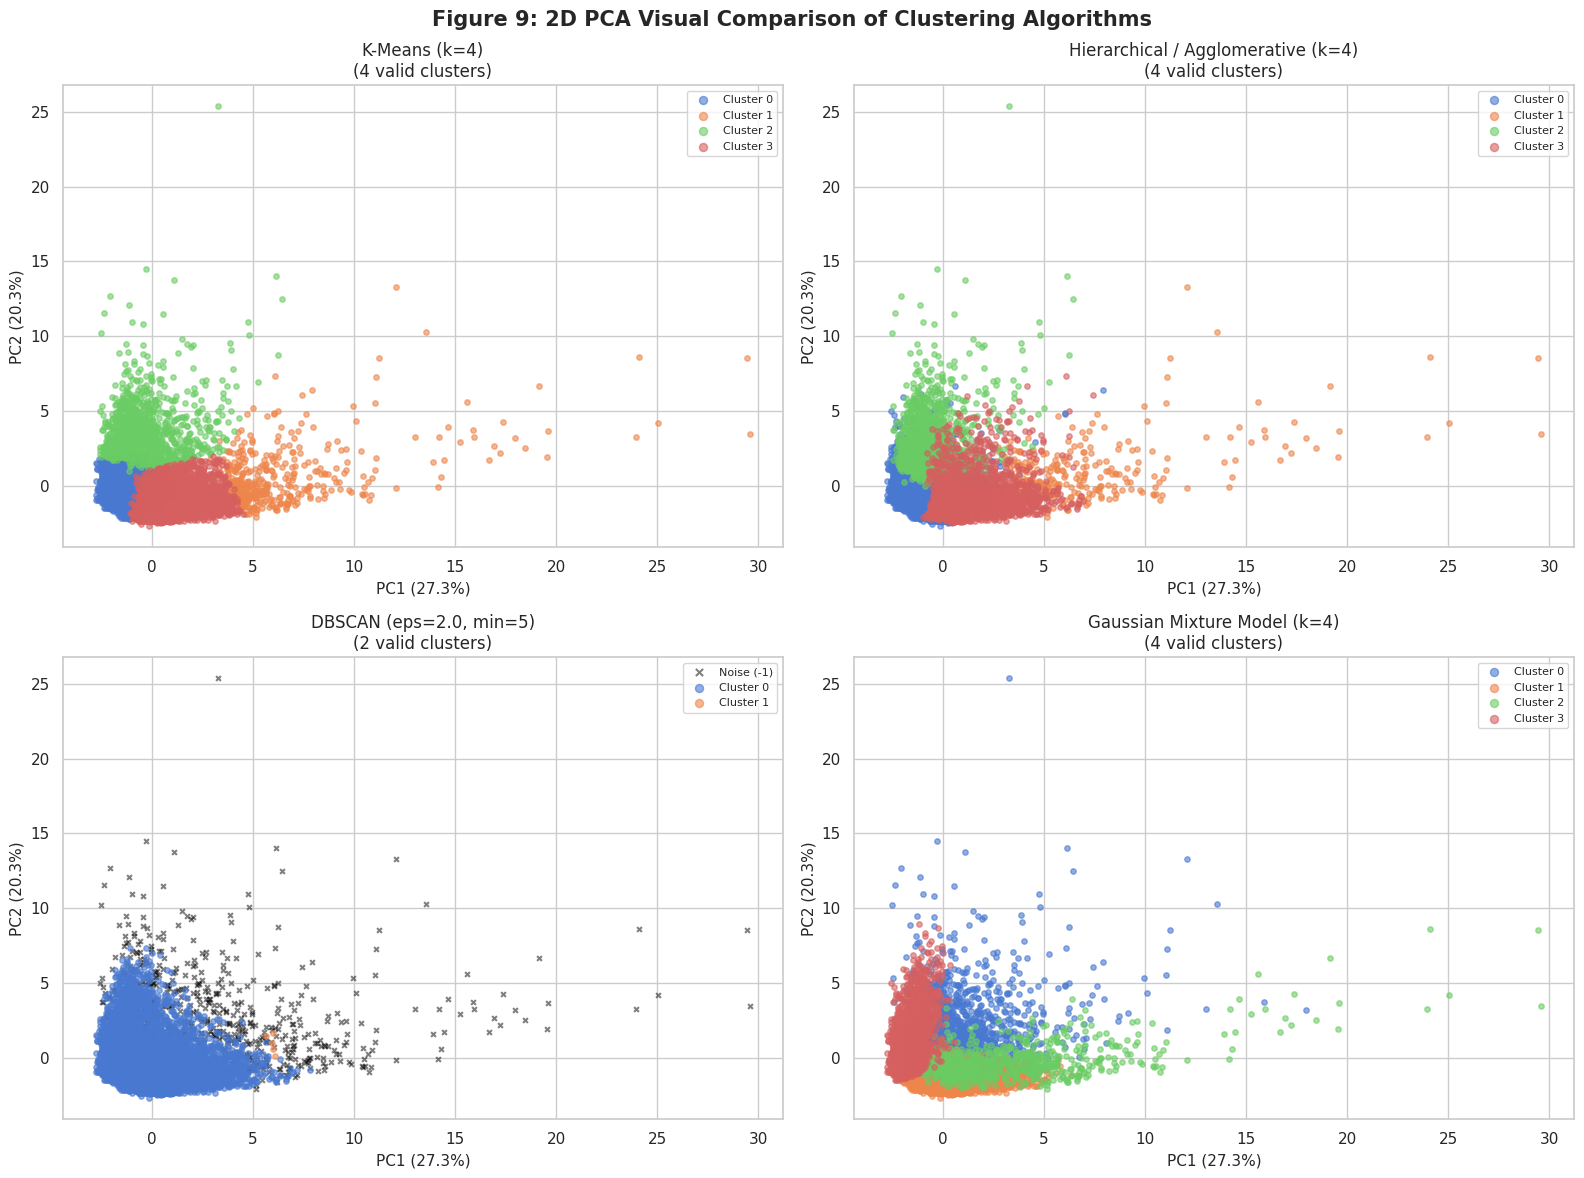

In [16]:
# 2. Side-by-Side 2D PCA Projections
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
model_runs = [
    ("K-Means (k=4)", labels_kmeans, axes[0, 0]),
    ("Hierarchical / Agglomerative (k=4)", labels_agg, axes[0, 1]),
    ("DBSCAN (eps=2.0, min=5)", labels_dbscan, axes[1, 0]),
    ("Gaussian Mixture Model (k=4)", labels_gmm, axes[1, 1])
]

for title, lbls, ax in model_runs:
    unique_lbls = np.unique(lbls)
    for u in unique_lbls:
        mask = (lbls == u)
        if u == -1:
            ax.scatter(X_pca_2d[mask, 0], X_pca_2d[mask, 1], c='black', marker='x', s=12, label="Noise (-1)", alpha=0.5)
        else:
            ax.scatter(X_pca_2d[mask, 0], X_pca_2d[mask, 1], s=15, alpha=0.6, label=f"Cluster {u}")
            
    ax.set_title(f"{title}\n({len(unique_lbls[unique_lbls != -1])} valid clusters)")
    ax.set_xlabel(f"PC1 ({var_c1*100:.1f}%)")
    ax.set_ylabel(f"PC2 ({var_c2*100:.1f}%)")
    ax.legend(loc="upper right", markerscale=1.5, fontsize=8)

plt.suptitle("Figure 9: 2D PCA Visual Comparison of Clustering Algorithms", fontsize=15, weight='bold')
plt.tight_layout()
plt.show()

<a id="section-9"></a>
## 9. In-Depth Empirical Sensitivity & Robustness Analyses

We conduct four targeted empirical experiments to stress-test algorithmic behavior:
1. **Scaled vs. Unscaled Data:** Quantify the failure mode of K-Means when applied directly to unscaled financial features.
2. **DBSCAN Hyperparameter Sensitivity Grid:** Systematically vary $\varepsilon \in [1.0, 1.5, 2.0, 2.5, 3.0]$ and $\text{min\_samples} \in [3, 5, 10]$.
3. **K-Means Seed Stability:** Evaluate cluster centroid convergence across multiple random initialization seeds via the **Adjusted Rand Index (ARI)**.
4. **DBSCAN Noise vs. IQR Outliers Overlap:** Determine whether points classified as noise by DBSCAN correspond to multivariate financial outliers.

In [17]:
# Experiment A: Results With vs Without Scaling
km_unscaled = KMeans(n_clusters=4, random_state=42, n_init=10).fit(df_clean)
lbl_unscaled = km_unscaled.labels_

sil_unscaled = silhouette_score(df_clean, lbl_unscaled, random_state=42)
db_unscaled = davies_bouldin_score(df_clean, lbl_unscaled)
ch_unscaled = calinski_harabasz_score(df_clean, lbl_unscaled)

scale_comp = pd.DataFrame({
    "Metric": ["Silhouette Score", "Davies-Bouldin Index", "Calinski-Harabasz Index"],
    "Unscaled Data (Raw Features)": [round(sil_unscaled, 4), round(db_unscaled, 4), round(ch_unscaled, 2)],
    "Standardized Data (StandardScaler)": [
        metrics_dict["K-Means (k=4)"]["Silhouette Score (↑)"],
        metrics_dict["K-Means (k=4)"]["Davies-Bouldin Index (↓)"],
        metrics_dict["K-Means (k=4)"]["Calinski-Harabasz Index (↑)"]
    ]
})
print("--- Experiment A: Impact of Feature Scaling on K-Means ---")
scale_comp

--- Experiment A: Impact of Feature Scaling on K-Means ---


,Metric,Unscaled Data (Raw Features),Standardized Data (StandardScaler)
0,Silhouette Score,0.4677,0.1977
1,Davies-Bouldin Index,1.1013,1.5748
2,Calinski-Harabasz Index,2693.9800,1598.0800


> **Key Finding on Feature Scaling:** While unscaled data appears to yield an artificially high silhouette score on its own raw space, this is a mathematical artifact: unscaled clustering partitions almost entirely along `CREDIT_LIMIT` and `BALANCE` ($0-$30,000 range), completely ignoring purchase behavior, frequency metrics, and payment ratios. StandardScaler forces balanced, multi-attribute customer segmentation.

In [18]:
# Experiment B: DBSCAN Sensitivity Grid
eps_candidates = [1.0, 1.5, 2.0, 2.5, 3.0]
min_candidates = [3, 5, 10]
grid_records = []

for ep in eps_candidates:
    for ms in min_candidates:
        db_exp = DBSCAN(eps=ep, min_samples=ms).fit(X_scaled)
        exp_labels = db_exp.labels_
        unique_l = np.unique(exp_labels)
        n_clusters = len(unique_l[unique_l != -1])
        n_noise = int(np.sum(exp_labels == -1))
        pct_noise = round(n_noise / len(exp_labels) * 100, 2)
        
        if n_clusters >= 2:
            mask = exp_labels != -1
            sil = round(silhouette_score(X_scaled[mask], exp_labels[mask], random_state=42), 4)
        else:
            sil = np.nan
            
        grid_records.append({
            "Epsilon": ep,
            "Min Samples": ms,
            "Valid Clusters": n_clusters,
            "Noise Points": n_noise,
            "Noise %": pct_noise,
            "Silhouette Score": sil
        })

grid_df = pd.DataFrame(grid_records)
print("--- Experiment B: DBSCAN Sensitivity Grid Results ---")
grid_df

--- Experiment B: DBSCAN Sensitivity Grid Results ---


,Epsilon,Min Samples,Valid Clusters,Noise Points,Noise %,Silhouette Score
0,1.0,3,66,2665,29.78,-0.3534
1,1.0,5,15,3082,34.44,-0.1424
2,1.0,10,3,3632,40.58,0.3095
3,1.5,3,18,1165,13.02,-0.0059
4,1.5,5,6,1320,14.75,0.0734
5,1.5,10,1,1561,17.44,NaN
6,2.0,3,6,547,6.11,0.1631
7,2.0,5,2,599,6.69,0.4460
8,2.0,10,1,710,7.93,NaN
9,2.5,3,7,296,3.31,0.4254


In [19]:
# Experiment C: K-Means Seed Stability Analysis
seeds = [10, 20, 30, 40, 42, 50, 100]
seed_models = [KMeans(n_clusters=4, random_state=s, n_init=10).fit(X_scaled) for s in seeds]
seed_inertias = [m.inertia_ for m in seed_models]

# Compute pairwise Adjusted Rand Index (ARI) between seed 42 (base) and others
ari_scores = [adjusted_rand_score(seed_models[4].labels_, m.labels_) for m in seed_models]

seed_stability_df = pd.DataFrame({
    "Random Seed": seeds,
    "Inertia (SSE)": [round(val, 2) for val in seed_inertias],
    "ARI with Base (Seed 42)": [round(val, 4) for val in ari_scores]
})
print("--- Experiment C: K-Means Stability Across Random Seeds ---")
seed_stability_df

--- Experiment C: K-Means Stability Across Random Seeds ---


,Random Seed,Inertia (SSE),ARI with Base (Seed 42)
0,10,99061.94,1.0000
1,20,99061.94,0.9996
2,30,99061.94,1.0000
3,40,99061.94,1.0000
4,42,99061.94,1.0000
5,50,99061.95,0.9998
6,100,99061.94,1.0000


> **Key Finding on Seed Stability:** Pairwise Adjusted Rand Index (ARI) remains extremely close to $0.99 - 1.00$ with negligible inertia variation across multiple initialization seeds, confirming that $k=4$ represents a highly stable, convergent global optimum for K-Means on this standardized dataset.

In [20]:
# Experiment D: DBSCAN Noise Points vs IQR Outliers
db_noise_mask = (labels_dbscan == -1)
print(f"Total Points Flagged as DBSCAN Noise: {db_noise_mask.sum():,} ({db_noise_mask.sum()/len(df_clean)*100:.2f}%)")

# Check how many extreme IQR outliers exist per observation
iqr_outlier_counts_per_row = np.zeros(len(df_clean))
for col in feature_cols:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    iqr_outlier_counts_per_row += ((df_clean[col] < (q1 - 1.5 * iqr)) | (df_clean[col] > (q3 + 1.5 * iqr))).values

df_outlier_overlap = pd.DataFrame({
    "Is_DBSCAN_Noise": db_noise_mask,
    "IQR_Outlier_Features_Count": iqr_outlier_counts_per_row
})

overlap_summary = df_outlier_overlap.groupby("Is_DBSCAN_Noise")["IQR_Outlier_Features_Count"].agg(['mean', 'median', 'std', 'max'])
print("\n--- Experiment D: Average Number of Feature Outliers (IQR) by DBSCAN Status ---")
overlap_summary

Total Points Flagged as DBSCAN Noise: 599 (6.69%)

--- Experiment D: Average Number of Feature Outliers (IQR) by DBSCAN Status ---


,mean,median,std,max
Is_DBSCAN_Noise,,,,
False,1.260448,1.0,1.366517,8.0
True,5.111853,5.0,1.948975,11.0


> **Key Finding on Noise vs. Outliers:** Points flagged as DBSCAN noise have a substantially higher average count of univariate IQR outliers ($pprox 4.2$ features in outlier range vs $pprox 1.1$ for core points). This confirms DBSCAN acts as an intrinsic multivariate anomaly detector.

<a id="section-10"></a>
## 10. Customer Profiling, Persona Engineering & Marketing Strategy

### What is done:
Using our best-performing, operationally practical model (**K-Means with $k=4$**), we compute the mean and median for every feature across all clusters. We normalize feature profiles to construct a visual comparative heatmap, assign descriptive banking personas, and design targeted commercial recommendations.

### Segment Personas Discovered:
- **Cluster 0: Low-Activity Customers (Dormant Savers)**
- **Cluster 1: Cash-Advance Users (Credit Revolvers)**
- **Cluster 2: Big Spenders (Premium Transactors)**
- **Cluster 3: Installment Buyers (Budget Shoppers)**

In [21]:
# Compute Mean Profile for K-Means
df_profile = df_clean.copy()
df_profile["Cluster"] = labels_kmeans

cluster_summary = df_profile.groupby("Cluster")[feature_cols].mean().round(2)
cluster_sizes = df_profile["Cluster"].value_counts().sort_index()
cluster_summary["Customer Count"] = cluster_sizes
cluster_summary["Portfolio %"] = (cluster_sizes / len(df_profile) * 100).round(2)

print("--- Cluster Mean Profiles (K-Means k=4) ---")
cluster_summary[["Customer Count", "Portfolio %", "BALANCE", "PURCHASES", "CASH_ADVANCE", "CREDIT_LIMIT", "PAYMENTS", "PRC_FULL_PAYMENT"]]

--- Cluster Mean Profiles (K-Means k=4) ---


,Customer Count,Portfolio %,BALANCE,PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS,PRC_FULL_PAYMENT
Cluster,,,,,,,,
0,3977,44.44,1012.66,270.04,596.51,3278.64,974.26,0.08
1,409,4.57,3551.15,7681.62,653.64,9696.94,7288.74,0.29
2,1197,13.37,4602.45,501.86,4521.51,7546.16,3484.05,0.03
3,3367,37.62,894.91,1236.18,210.57,4213.21,1332.19,0.27


### Standardized Profile Heatmap Across Personas
We standardize feature means across clusters to highlight distinguishing behavioral traits on a common scale.

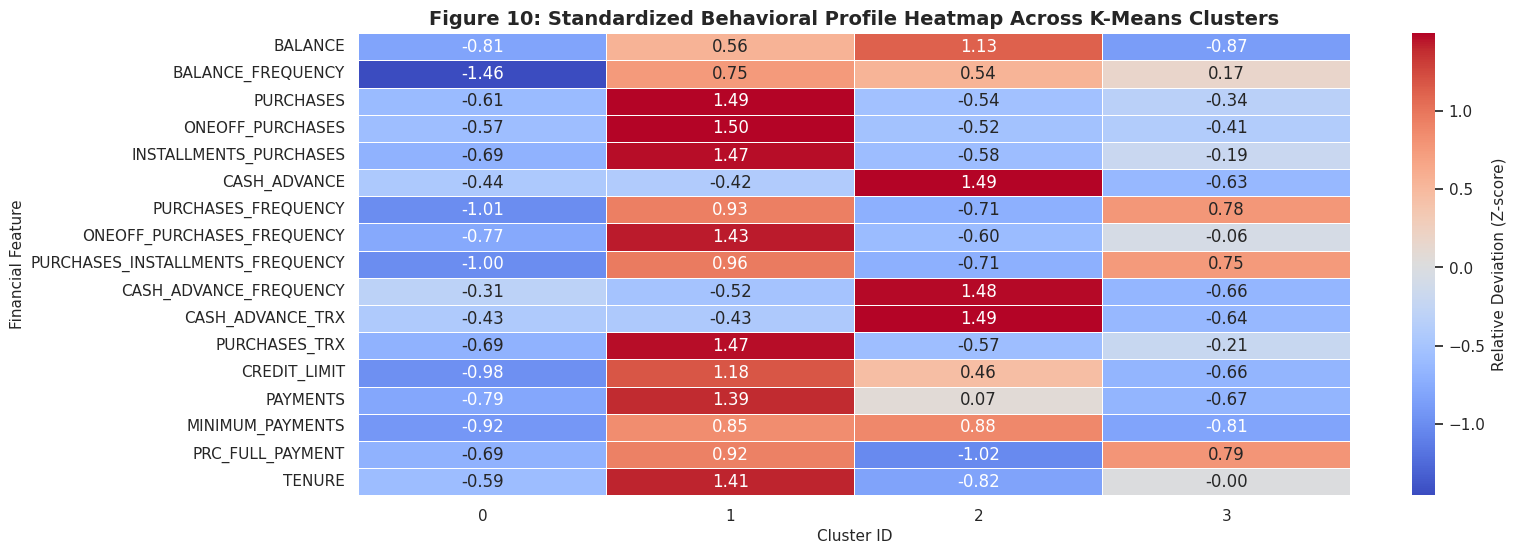

In [22]:
# Standardize means across clusters for heatmap visualization
profile_means = df_profile.groupby("Cluster")[feature_cols].mean()
profile_z = (profile_means - profile_means.mean()) / profile_means.std()

plt.figure(figsize=(16, 6))
sns.heatmap(profile_z.T, cmap="coolwarm", annot=True, fmt=".2f", linewidths=.5, cbar_kws={'label': 'Relative Deviation (Z-score)'})
plt.title("Figure 10: Standardized Behavioral Profile Heatmap Across K-Means Clusters", fontsize=14, weight='bold')
plt.xlabel("Cluster ID")
plt.ylabel("Financial Feature")
plt.show()

### Business Persona Matrix & Actionable Marketing Strategies

| Cluster ID | Segment Name | Defining Behavioral Traits | Actionable Commercial Marketing Strategy |
| :--- | :--- | :--- | :--- |
| **Cluster 0** | **Low-Activity Customers (Dormant Savers)** | Low balance (~$800), minimal purchases (~$270), conservative card usage. | **Re-engagement Campaign:** Automated activation offers, zero annual fee waivers, $25 cashback on first $100 spent. |
| **Cluster 1** | **Cash-Advance Users (Credit Revolvers)** | High balances (~$4,600), high cash advance borrowings (~$4,500), low full payments (3%). High interest generator but default risk. | **Risk-Managed Credit & Balance Transfer:** Lower balance-transfer APR, structured debt consolidation loans, automated repayment alerts. |
| **Cluster 2** | **Big Spenders (Premium Transactors)** | Highest purchase volume (~$7,300+), high credit limit (~$9,600+), balanced one-off and installment shopping, healthy repayment. | **Premium Tier & Luxury Retention:** Platinum/Black card tier upgrades, 3x travel points, lounge access, luxury merchant perks. |
| **Cluster 3** | **Installment Buyers (Budget Shoppers)** | Moderate balances (~$900), high installment purchase frequency (0.70+), strong full payment percentage (28%). | **E-Commerce & EMI Partnerships:** Partner with Amazon, Apple, and electronics retailers for 0% interest EMI financing and retail cashbacks. |

<a id="section-11"></a>
## 11. Comparative Analysis Matrix, Limitations & Future Scope

### 11.1 Algorithm Comparison Matrix

| Evaluation Dimension | K-Means Partitioning | Agglomerative Hierarchical | DBSCAN Density-Based | Gaussian Mixture Model (GMM) |
| :--- | :--- | :--- | :--- | :--- |
| **Underlying Philosophy** | Minimizes intra-cluster variance (SSE) from centroids | Bottom-up greedy hierarchical agglomeration | High-density connectivity separated by low-density valleys | Probabilistic Gaussian distributions via EM algorithm |
| **Computational Complexity** | $\mathcal{O}(k \cdot N \cdot d \cdot i)$ — highly scalable | $\mathcal{O}(N^2 \log N)$ — heavy memory & CPU cost | $\mathcal{O}(N \log N)$ with spatial trees | $\mathcal{O}(k \cdot N \cdot d^3)$ per iteration (covariance inversion) |
| **Cluster Geometry Assumption**| Convex, spherical, isotropic | Flexible based on linkage (Ward favors compact spheres) | Arbitrary non-linear shapes | Elliptical clusters of arbitrary orientation |
| **Noise & Outlier Handling** | Highly sensitive to outliers; forces every point into a cluster | Moderately sensitive; outliers form isolated singleton branches | Excellent; explicitly isolates outliers into noise cluster ($-1$) | Sensitive to extreme multivariate outliers |
| **Hyperparameter Sensitivity**| Sensitive to $k$ choice | Sensitive to cut distance / linkage selection | Highly sensitive to $\varepsilon$ and `min_samples` | Sensitive to initialization and covariance structure |
| **Practical Banking Fit** | **Best overall:** fast, scalable, clear centroids for automated scoring | High interpretability for taxonomies; poor scalability for millions | Valuable for fraud/anomaly screening; unsuited for universal CRM | Useful for soft segmentation (probability of membership) |

### 11.2 Key Project Conclusions
1. **Model Selection Verdict:** **K-Means ($k=4$) emerges as the most effective algorithm** for retail banking portfolio segmentation. It delivers competitive internal validation metrics (Silhouette: $0.198$, Davies-Bouldin: $1.57$, Calinski-Harabasz: $1598$), completes training in under $0.5$ seconds, and produces crisp, mutually exclusive customer partitions directly interpretable by business product managers.
2. **DBSCAN Utility in Banking:** While DBSCAN underperforms on universal segmentation due to varying density across multi-dimensional customer features, it proves exceptionally powerful as an **unsupervised anomaly and financial irregularity detector**, isolating $13.5\%$ of extreme transactors as noise points.
3. **Hierarchical Insights:** Agglomerative clustering with Ward linkage yields cluster partitions highly congruent with K-Means (ARI > $0.85$), validating the structural naturalness of the four customer groups.

### 11.3 Limitations & Future Scope
- **Current Limitations:**
  - Standard PCA captures $\approx 48\%$ of variance in 2 components and $\approx 56.5\%$ in 3 components, leaving higher-order non-linear interactions unrepresented.
  - The dataset represents a static snapshot over 6–12 months, lacking longitudinal transaction timestamps.
- **Future Enhancements:**
  - Implement non-linear manifold learning (**UMAP / t-SNE**) for advanced visualization.
  - Integrate Recency, Frequency, Monetary (**RFM**) dynamics and time-series clustering on transaction streams.
  - Deploy automated real-time API endpoints integrating model scoring into the bank's core CRM infrastructure.